## Raster Data

In scikit-map, the class `RasterData` is responsible to implement reading, processing and writing operations. To understand how it works let's load the NDVI toy dataset provided by default.

In [1]:
import os

os.environ["PROJ_LIB"] = "/skmap/lib/python3.12/site-packages/rasterio/proj_data"
os.environ["PROJ_DATA"] = "/skmap/lib/python3.12/site-packages/rasterio/proj_data"

In [2]:
import warnings

import pandas as pd

warnings.filterwarnings("ignore")

from skmap.data import toy
from skmap.io import RasterData
backend='numpy' # numba, numpy

# Load the gappy NDVI time-series from the toy layers.yaml catalogue.
rdata = (
    RasterData.from_yaml(str(toy.LAYERS_YAML), base_path=str(toy.DATA_DIR), backend=backend)
    .filter("band == 'ndvi' and variant == 'gappy'")
    .read()
)


2026-09-06 13:11:29,960	WARNING services.py:2248 -- WARNING: The object store is using /tmp/ray instead of /dev/shm because /dev/shm has only 67108864 bytes available. This will harm performance! You may be able to free up space by deleting files in /dev/shm. If you are inside a Docker container, you can increase /dev/shm size by passing '--shm-size=10.24gb' to 'docker run' (or add it to the run_options list in a Ray cluster config). Make sure to set this to more than 30% of available RAM.


2026-09-06 13:11:33,163	INFO worker.py:2024 -- Started a local Ray instance.


A `RasterData` instance is basically a Pandas [DataFrame](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html) accessible through the `info` attribute

In [3]:
rdata.info

,feature,input_path,input_band,start_date,end_date,is_common,name,band,variant,season,year
0,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2014-12-02,2015-03-20,False,ndvi_winter,ndvi,gappy,winter,2014.0
1,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2015-03-21,2015-06-24,False,ndvi_spring,ndvi,gappy,spring,2015.0
2,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2015-06-25,2015-09-12,False,ndvi_summer,ndvi,gappy,summer,2015.0
3,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2015-09-13,2015-12-01,False,ndvi_fall,ndvi,gappy,fall,2015.0
4,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2015-12-02,2016-03-20,False,ndvi_winter,ndvi,gappy,winter,2015.0
5,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2016-03-21,2016-06-24,False,ndvi_spring,ndvi,gappy,spring,2016.0
6,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2016-06-25,2016-09-12,False,ndvi_summer,ndvi,gappy,summer,2016.0
7,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2016-09-13,2016-12-01,False,ndvi_fall,ndvi,gappy,fall,2016.0
8,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2016-12-02,2017-03-20,False,ndvi_winter,ndvi,gappy,winter,2016.0
9,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2017-03-21,2017-06-24,False,ndvi_spring,ndvi,gappy,spring,2017.0


...and a 2-D Numpy array, the `array` attribute with shape `(N, H*W)` where `N` is the number of raster layers (time) and `H*W` the flattened spatial extent. Use `.get()` to materialize it as a numpy array.

In [4]:
rdata.array.shape

(24, 65536)

The `array` can be filtered and subset using `info`. 

In [5]:
rdata.array.get()[
    (rdata.info["end_date"] >= pd.Timestamp("2020-01-01")).values, :
].shape

(4, 65536)

However you can use the `filter_date` method to subset the time series by date.

In [6]:
rdata.filter_date("2020-01-01", return_array=True).shape

(3, 65536)

The data can be visualized through a static plot

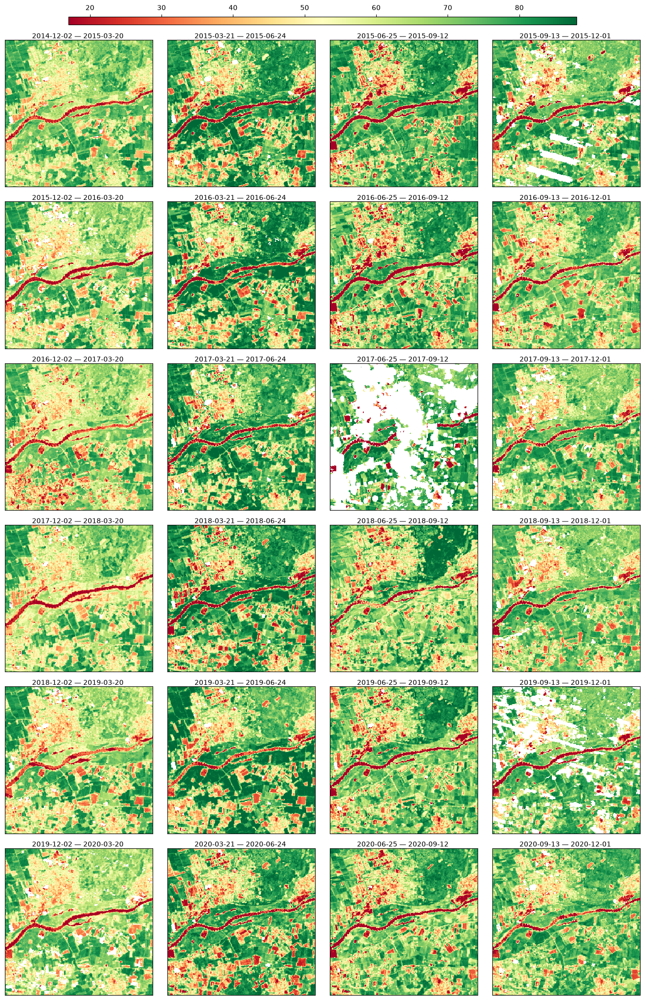

In [7]:
rdata.plot(cmap="RdYlGn", img_title_text="{start_date:%Y-%m-%d} — {end_date:%Y-%m-%d} ")

... and an animation.

In [8]:
rdata.animate(cmap="RdYlGn", img_title_text="date", n_jobs=8)

After visualizing the data, it's possible to notice some data gaps in the NDVI series. 

`Scikit-map` supports several data processing task including **gapfilling, smoothing, time aggregation, math operations, trend analysis, etc**.  Let's run a gapfilling process and visualize the result.

In [9]:
from skmap.io import process

rdata = rdata.run(process.SeasConvFill(season_size=4), drop_input=True)
rdata.animate(cmap="RdYlGn", img_title_text="date")

The `info` attribute shows that the new feature `ndvi_seasconv` was created, and the old one `ndvi` was deleted according to `drop_input=True`.

In [10]:
rdata.info

,feature,input_path,input_band,start_date,end_date,is_common,name,band,variant,season,year
0,ndvi_seasconv,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2014-12-02,2015-03-20,False,ndvi_seasconv_20141202_20150320,NaN,NaN,NaN,NaN
1,ndvi_seasconv,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2015-03-21,2015-06-24,False,ndvi_seasconv_20150321_20150624,NaN,NaN,NaN,NaN
2,ndvi_seasconv,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2015-06-25,2015-09-12,False,ndvi_seasconv_20150625_20150912,NaN,NaN,NaN,NaN
3,ndvi_seasconv,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2015-09-13,2015-12-01,False,ndvi_seasconv_20150913_20151201,NaN,NaN,NaN,NaN
4,ndvi_seasconv,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2015-12-02,2016-03-20,False,ndvi_seasconv_20151202_20160320,NaN,NaN,NaN,NaN
5,ndvi_seasconv,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2016-03-21,2016-06-24,False,ndvi_seasconv_20160321_20160624,NaN,NaN,NaN,NaN
6,ndvi_seasconv,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2016-06-25,2016-09-12,False,ndvi_seasconv_20160625_20160912,NaN,NaN,NaN,NaN
7,ndvi_seasconv,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2016-09-13,2016-12-01,False,ndvi_seasconv_20160913_20161201,NaN,NaN,NaN,NaN
8,ndvi_seasconv,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2016-12-02,2017-03-20,False,ndvi_seasconv_20161202_20170320,NaN,NaN,NaN,NaN
9,ndvi_seasconv,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2017-03-21,2017-06-24,False,ndvi_seasconv_20170321_20170624,NaN,NaN,NaN,NaN


`RasterData` supports the execution of multiple processing tasks through [fluent interface](https://en.wikipedia.org/wiki/Fluent_interface) relying extensively on method chaining.

Let's testing it by
1. **Loading** again the gappy NDVI time-series, 
2. Running the **gapfilling** approach, and 
3. **aggregating** the gapffiled data by year using two time reducers operations (standard deviation and percentile 50th).

In [11]:
rdata = (
    RasterData.from_yaml(str(toy.LAYERS_YAML), base_path=str(toy.DATA_DIR), backend=backend)
    .filter("band == 'ndvi' and variant == 'gappy'")
    .read()
    .run(
        process.SeasConvFill(season_size=4),
        drop_input=True,
        # Renaming back the output to ndvi
    )
    .rename(
        features={"ndvi_seasconv": "ndvi"}
        # Running yearly aggregation by std. and percentile 50th
    )
    .run(
        process.TimeAggregate(
            time=[process.TimeEnum.YEARLY], operations=["p50", "std"]
        ),
        feature=["ndvi"],
    )
)

rdata.info

(_call_worker pid=2811182) /skmap/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
(_call_worker pid=2811182)   return fnb._ureduce(a,


,feature,input_path,input_band,start_date,end_date,is_common,name,band,variant,season,year
0,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2014-12-02,2015-03-20,False,ndvi_seasconv_20141202_20150320,NaN,NaN,NaN,NaN
1,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2015-03-21,2015-06-24,False,ndvi_seasconv_20150321_20150624,NaN,NaN,NaN,NaN
2,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2015-06-25,2015-09-12,False,ndvi_seasconv_20150625_20150912,NaN,NaN,NaN,NaN
3,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2015-09-13,2015-12-01,False,ndvi_seasconv_20150913_20151201,NaN,NaN,NaN,NaN
4,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2015-12-02,2016-03-20,False,ndvi_seasconv_20151202_20160320,NaN,NaN,NaN,NaN
5,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2016-03-21,2016-06-24,False,ndvi_seasconv_20160321_20160624,NaN,NaN,NaN,NaN
6,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2016-06-25,2016-09-12,False,ndvi_seasconv_20160625_20160912,NaN,NaN,NaN,NaN
7,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2016-09-13,2016-12-01,False,ndvi_seasconv_20160913_20161201,NaN,NaN,NaN,NaN
8,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2016-12-02,2017-03-20,False,ndvi_seasconv_20161202_20170320,NaN,NaN,NaN,NaN
9,ndvi,/root/scikit-map/skmap/data/toy/ndvi/gappy/ndv...,1,2017-03-21,2017-06-24,False,ndvi_seasconv_20170321_20170624,NaN,NaN,NaN,NaN


Let's visualize the result of the annual aggregation (percentile 50th):

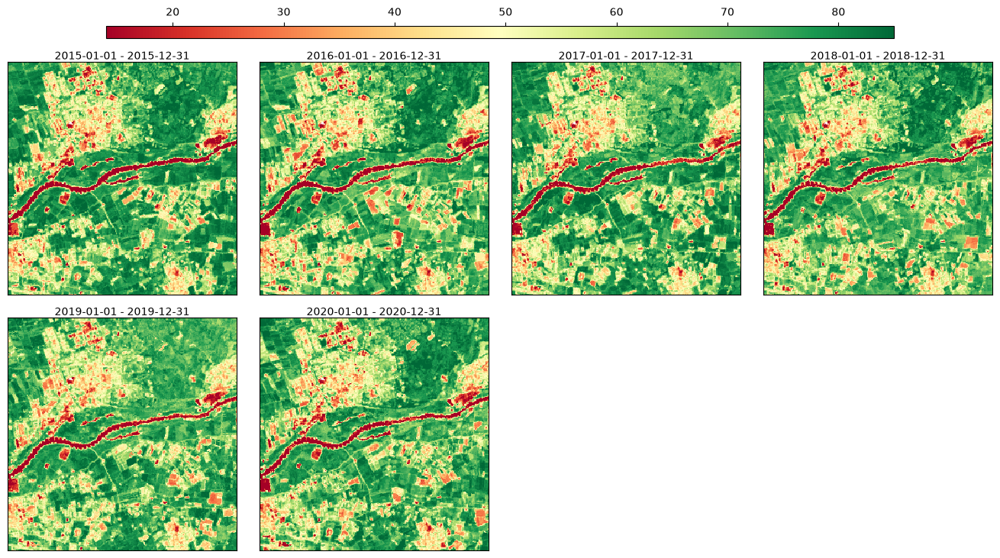

In [12]:
rdata.plot(features=["ndvi_yearly_p50"], cmap="RdYlGn", img_title_text="date")

### Features

RasterData supports different set of layer, organizing them by features. **Multiple bands** of a raster time-series, a for example NDVI and SWIR-1 band, can be organized as different features. However it's also possible to have **different time-series** size in each feature, and even **static raster layers** without a specific date interval.

To demonstrate that let's load another toy dataset which provides multi feature support.

<Axes: ylabel='feature'>

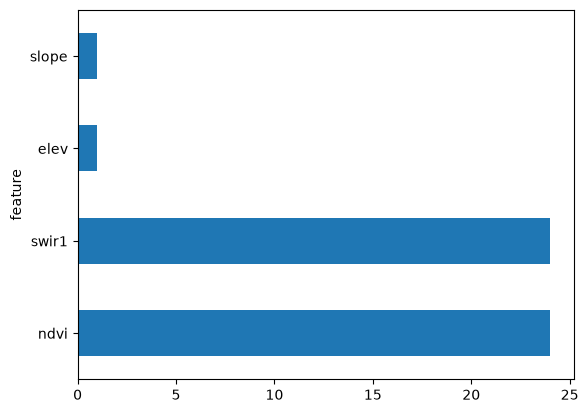

In [13]:
# Multi-feature dataset: NDVI + SWIR-1 + static (loaded from layers.yaml)
rdata = (
    RasterData.from_yaml(str(toy.LAYERS_YAML), base_path=str(toy.DATA_DIR), backend=backend)
    .filter("variant != 'gappy'")
    .read()
)
rdata.info["feature"].value_counts().plot(kind="barh")


How the common features look like?

In [14]:
rdata.filter("is_common == True").info


,feature,input_path,input_band,start_date,end_date,is_common,name,band,variant,season,year
0,elev,/root/scikit-map/skmap/data/toy/static/elev.lo...,1,NaT,NaT,True,elev,NaN,NaN,NaN,NaN
1,slope,/root/scikit-map/skmap/data/toy/static/slope.p...,1,NaT,NaT,True,slope,NaN,NaN,NaN,NaN


In a multi feature `RasterData`, most of the processing tasks are executed for each feature separately. 

To demonstrate it, let's run the annual aggregation by percentile 95th.

In [15]:
from skmap.io import process

rdata = rdata.run(
    process.TimeAggregate(time=[process.TimeEnum.YEARLY], operations=["p95"])
)

And you can see two more features in `rdata`.

<Axes: ylabel='feature'>

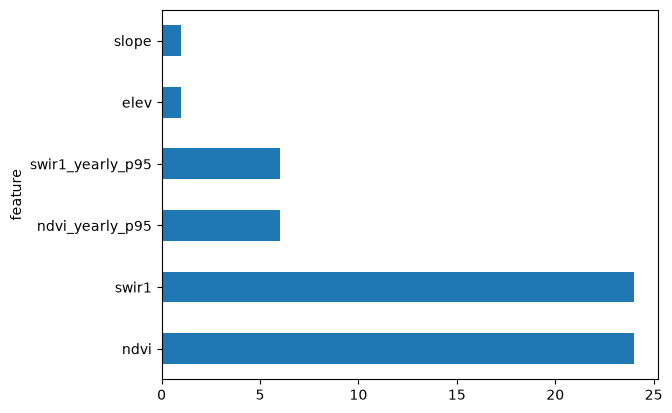

In [16]:
rdata.info["feature"].value_counts().plot(kind="barh")

Let's visualize one of them.

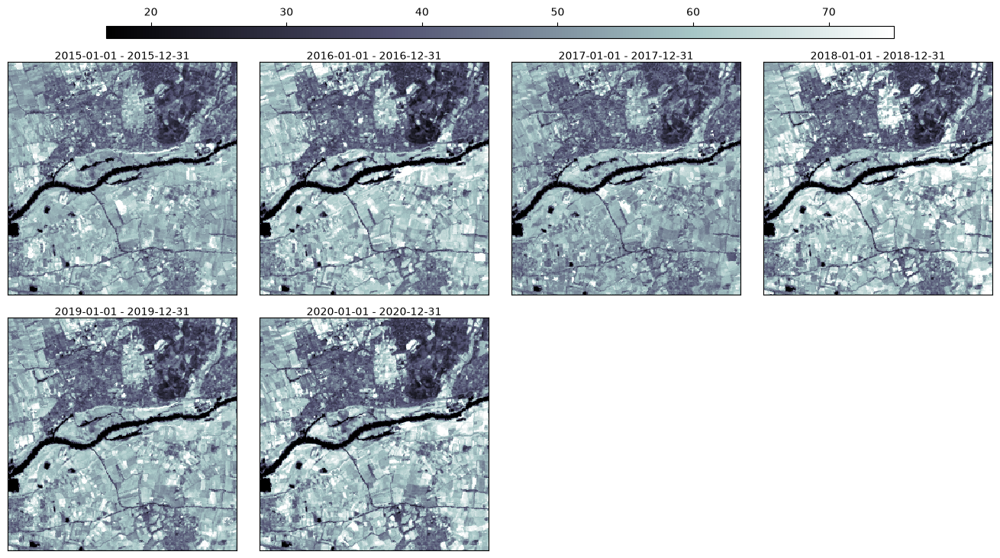

In [17]:
rdata.plot(features=["swir1_yearly_p95"], cmap="bone", img_title_text="date")

### Multi-column selection and runners

Catalogue sources (YAML, STAC) add one `info` column per `{variable}`
placeholder — the toy catalogue carries `band`, `variant`, `season` and
`year` alongside the standard columns. Use `select(...)` to filter layers
by any of these columns instead of only `feature`:

In [18]:
# Multi-column selection: NDVI winter composites across all years
from skmap.data import toy
from skmap.io import RasterData

rdata_multi = (
    RasterData.from_yaml(str(toy.LAYERS_YAML), base_path=str(toy.DATA_DIR))
    .filter("variant != 'gappy'")
    .read()
)
rdata_multi.select(feature="ndvi", season="winter").info[["feature", "name", "year", "season"]]

,feature,name,year,season
0,ndvi,ndvi_winter,2014.0,winter
1,ndvi,ndvi_winter,2015.0,winter
2,ndvi,ndvi_winter,2016.0,winter
3,ndvi,ndvi_winter,2017.0,winter
4,ndvi,ndvi_winter,2018.0,winter
5,ndvi,ndvi_winter,2019.0,winter


Runners can likewise resolve their input bands by a variable column and
compute **one output band per partition**, regardless of how the catalogue
was organised. Pass `match_col` (the column holding the band names) and `by`
(the partition columns) to `run`:

In [19]:
from skmap.io import process

# One normalised-difference band per (year, season): "ndvi" and "swir1" are
# resolved from the `band` column, not from `name` or `feature`.
rdata_multi = rdata_multi.run(
    process.NormalizedDifference("ndvi", "swir1"),
    match_col="band",
    by=["year", "season"],
    outname="nd_swir",
)
rdata_multi.filter("name.str.startswith('nd_swir')").info[["feature", "name", "year", "season"]]

,feature,name,year,season
0,nd_swir,nd_swir_2014_winter,NaN,NaN
1,nd_swir,nd_swir_2015_fall,NaN,NaN
2,nd_swir,nd_swir_2015_spring,NaN,NaN
3,nd_swir,nd_swir_2015_summer,NaN,NaN
4,nd_swir,nd_swir_2015_winter,NaN,NaN
5,nd_swir,nd_swir_2016_fall,NaN,NaN
6,nd_swir,nd_swir_2016_spring,NaN,NaN
7,nd_swir,nd_swir_2016_summer,NaN,NaN
8,nd_swir,nd_swir_2016_winter,NaN,NaN
9,nd_swir,nd_swir_2017_fall,NaN,NaN
